# Unveiling the Android App Market: Google Play Store Analysis
**Objective:** Clean real-world app store data, explore categories, ratings, sizes and pricing, and run sentiment analysis on user reviews.

**Tech stack:** Python, pandas, numpy, matplotlib, seaborn, NLTK VADER, plotly

> **Note:** `googleplaystore.csv` and `googleplaystore_user_reviews.csv` here are practice files that copy the structure and the messy formatting of the Kaggle "Google Play Store Apps" dataset (`Installs` as text like `10,000+`, `Size` like `19M`, `Price` like `$4.99`, duplicates and missing ratings). For your final submission, download the real dataset from Kaggle and run the same notebook on it. Real column names contain spaces (for example `Content Rating`, `Last Updated`), and the real reviews file already has its own `Sentiment` column, so adjust names where needed and compare VADER with that column if you like.

## 0. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

## 1. Load both datasets separately

In [3]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("Apps:", apps.shape)
print("Reviews:", reviews.shape)
apps.head()

Apps: (3150, 11)
Reviews: (8334, 2)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last_Updated
0,Pro Scanner 56,EDUCATION,3.8,2,Varies with device,100+,Free,0,Everyone 10+,Education,"July 11, 2018"
1,Ultra Box 236,MEDICAL,4.4,20,58.0M,"1,000+",Free,0,Everyone,Medical,"April 30, 2016"
2,Fresh Pal 859,PHOTOGRAPHY,3.1,82,2.3M,"10,000+",Free,0,Everyone,Photography,"February 13, 2017"
3,Fresh Coach 35,GAME,NaN,13,43300k,"1,000+",Free,0,Everyone,Game,"August 10, 2017"
4,Fresh Studio 248,SOCIAL,4.0,49,5.3M,"5,000+",Free,0,Mature 17+,Social,"December 11, 2016"


In [4]:
apps.info()
print()
print("Nulls (apps):")
print(apps.isnull().sum())
print()
print("Nulls (reviews):")
print(reviews.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             3150 non-null   str    
 1   Category        3150 non-null   str    
 2   Rating          2772 non-null   float64
 3   Reviews         3150 non-null   int64  
 4   Size            3150 non-null   str    
 5   Installs        3150 non-null   str    
 6   Type            3147 non-null   str    
 7   Price           3150 non-null   str    
 8   Content_Rating  3150 non-null   str    
 9   Genres          3150 non-null   str    
 10  Last_Updated    3150 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 270.8 KB

Nulls (apps):
App                 0
Category            0
Rating            378
Reviews             0
Size                0
Installs            0
Type                3
Price               0
Content_Rating      0
Genres              0
Last_Updated        0
dt

**Problems found:** _List what is wrong with the raw data (text numbers, duplicates, missing values...)._

## 2. Data cleaning
_Checklist: fix data types (Installs, Size, Price...), handle nulls, remove duplicates_

In [5]:
n0 = len(apps)
apps = apps.drop_duplicates().reset_index(drop=True)
print(f"Removed {n0 - len(apps)} duplicate rows")

# Installs: '10,000+' -> 10000
apps["Installs"] = apps["Installs"].astype(str).str.replace(r"[+,]", "", regex=True).astype(int)

# Price: '$4.99' -> 4.99
apps["Price"] = apps["Price"].astype(str).str.replace("$", "", regex=False).astype(float)

# Reviews: text -> int
apps["Reviews"] = pd.to_numeric(apps["Reviews"], errors="coerce").astype("Int64")

# Last updated -> datetime
apps["Last_Updated"] = pd.to_datetime(apps["Last_Updated"])

Removed 150 duplicate rows


In [6]:
# Size: '19M' -> 19.0, '800k' -> 0.8, 'Varies with device' -> NaN
def parse_size(s):
    s = str(s)
    if s.endswith("M"):
        return float(s[:-1])
    if s.endswith("k"):
        return float(s[:-1]) / 1000
    return np.nan

apps["Size_MB"] = apps["Size"].apply(parse_size)

# Type: rebuild from Price where it is missing
missing_type = apps["Type"].isna()
apps.loc[missing_type, "Type"] = np.where(apps.loc[missing_type, "Price"] > 0, "Paid", "Free")

print(apps.dtypes)
print()
print("Nulls after cleaning:")
print(apps.isnull().sum())

App                          str
Category                     str
Rating                   float64
Reviews                    Int64
Size                         str
Installs                   int64
Type                         str
Price                    float64
Content_Rating               str
Genres                       str
Last_Updated      datetime64[us]
Size_MB                  float64
dtype: object

Nulls after cleaning:
App                 0
Category            0
Rating            360
Reviews             0
Size                0
Installs            0
Type                0
Price               0
Content_Rating      0
Genres              0
Last_Updated        0
Size_MB           380
dtype: int64


**Decisions:** _Explain what you did about the missing `Rating` and `Size_MB` values. Here they are kept as NaN and each analysis drops the missing values it needs. Is that a good choice? Why not fill them with the mean?_

In [7]:
reviews = reviews.dropna(subset=["Translated_Review"]).reset_index(drop=True)
print("Reviews after dropping nulls:", reviews.shape)

Reviews after dropping nulls: (7917, 2)


## 3. Category analysis
_Checklist: bar chart of app distribution across categories; which are most saturated?_

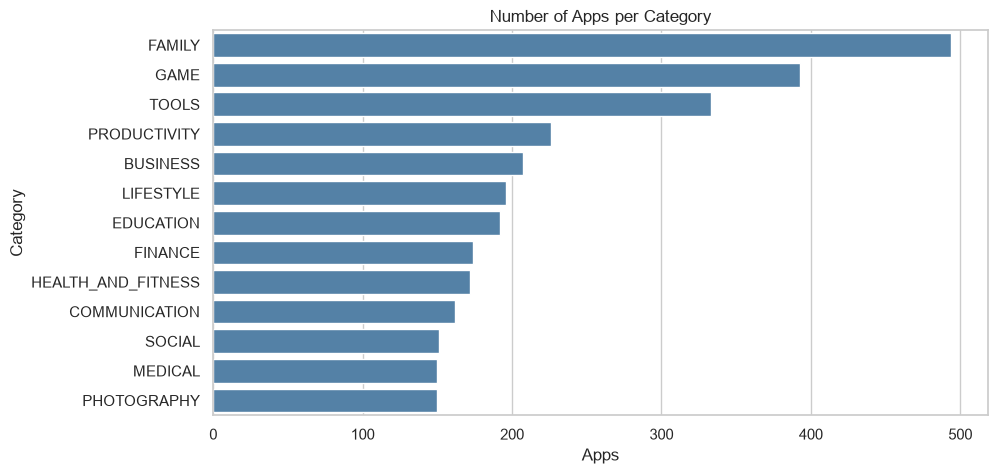

In [8]:
cat_counts = apps["Category"].value_counts()

sns.barplot(x=cat_counts.values, y=cat_counts.index, color="steelblue")
plt.title("Number of Apps per Category")
plt.xlabel("Apps")
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 4. Ratings analysis
_Checklist: distribution of ratings; average rating by category_

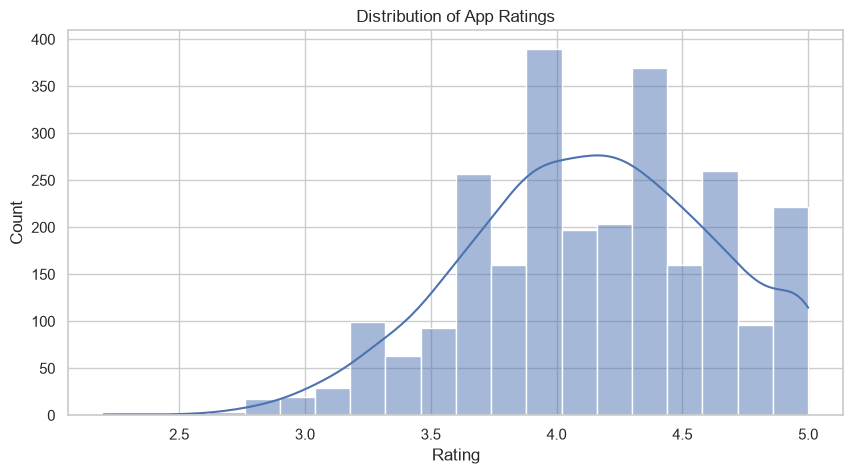

Average rating: 4.13


In [9]:
rated = apps.dropna(subset=["Rating"])

sns.histplot(rated["Rating"], bins=20, kde=True)
plt.title("Distribution of App Ratings")
plt.show()
print("Average rating:", round(rated["Rating"].mean(), 2))

**Observation:** _Write 2-3 sentences about what this output shows._

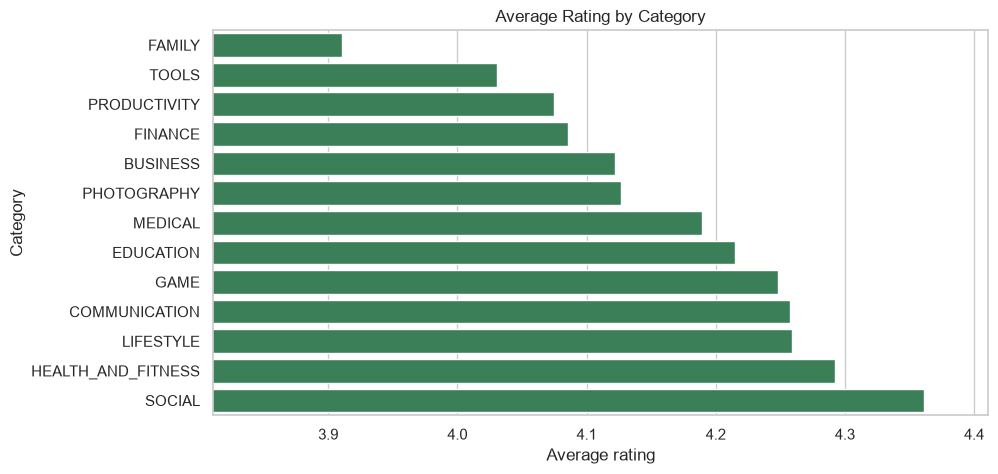

In [10]:
avg_rating = rated.groupby("Category")["Rating"].mean().sort_values()

sns.barplot(x=avg_rating.values, y=avg_rating.index, color="seagreen")
plt.xlim(avg_rating.min() - 0.1, avg_rating.max() + 0.05)
plt.title("Average Rating by Category")
plt.xlabel("Average rating")
plt.show()

**Observation:** _Which categories have the highest and lowest average rating? Is the difference large or small?_

## 5. Size and installs
_Checklist: scatter plot of size vs installs; is there a correlation?_

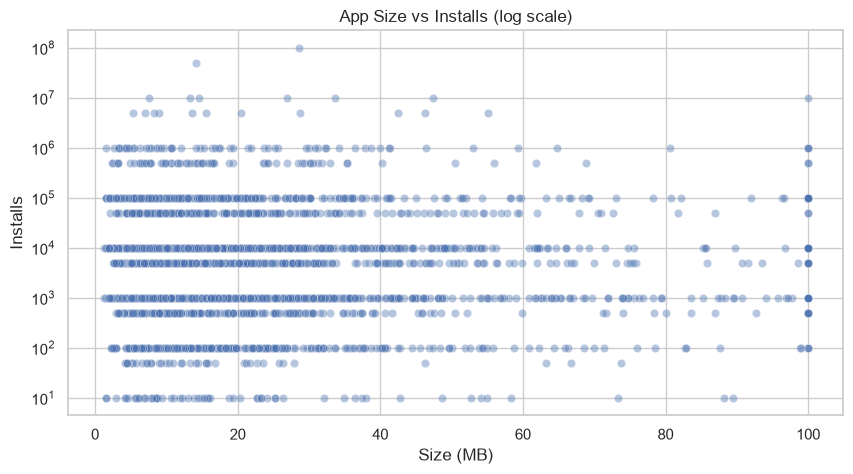

Correlation (size vs log installs): 0.011


In [11]:
sz = apps.dropna(subset=["Size_MB"])

sns.scatterplot(data=sz, x="Size_MB", y="Installs", alpha=0.4)
plt.yscale("log")
plt.title("App Size vs Installs (log scale)")
plt.xlabel("Size (MB)")
plt.show()

corr = sz["Size_MB"].corr(np.log10(sz["Installs"]))
print(f"Correlation (size vs log installs): {corr:.3f}")

**Observation:** _Is there a relationship? What does the correlation value tell you? Why is the log scale used for installs?_

## 6. Pricing analysis
_Checklist: paid vs free; price distribution for paid apps; revenue estimate by category_

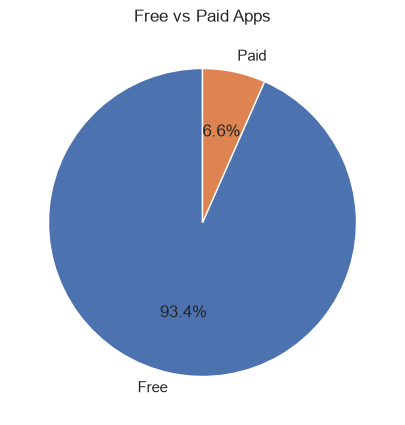

In [12]:
type_counts = apps["Type"].value_counts()
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Free vs Paid Apps")
plt.show()

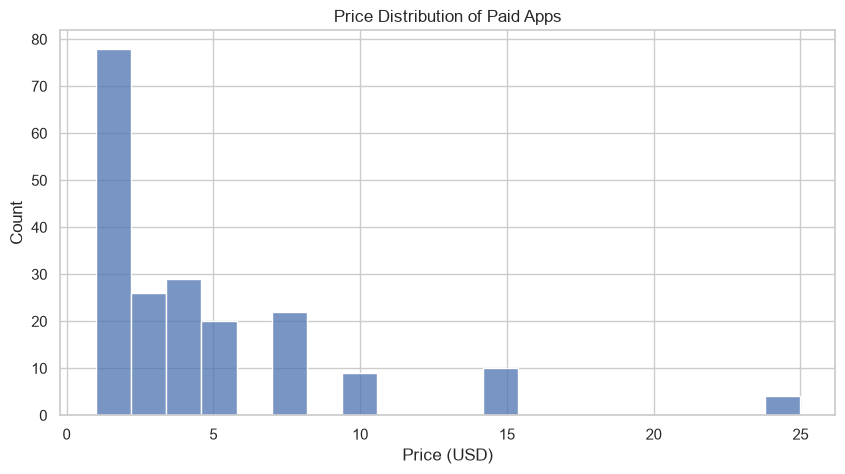

count    198.00
mean       4.57
std        4.49
min        0.99
25%        1.99
50%        2.99
75%        4.99
max       24.99
Name: Price, dtype: float64


In [13]:
paid = apps[apps["Type"] == "Paid"].copy()

sns.histplot(paid["Price"], bins=20)
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price (USD)")
plt.show()
print(paid["Price"].describe().round(2))

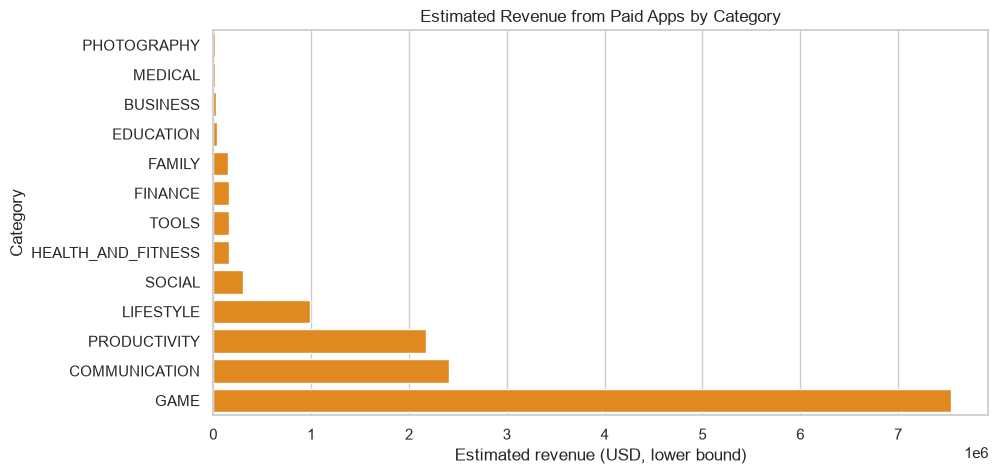

In [14]:
# Revenue estimate = price x installs (installs is a lower bound, so this is a minimum estimate)
paid["Revenue_Est"] = paid["Price"] * paid["Installs"]
rev_cat = paid.groupby("Category")["Revenue_Est"].sum().sort_values()

sns.barplot(x=rev_cat.values, y=rev_cat.index, color="darkorange")
plt.title("Estimated Revenue from Paid Apps by Category")
plt.xlabel("Estimated revenue (USD, lower bound)")
plt.show()

**Observation:** _What share of apps is paid? Do paid apps get fewer installs? Which categories earn the most from paid apps, and why might that be misleading?_

## 7. Sentiment analysis on user reviews
_Checklist: classify reviews as positive/negative/neutral using VADER_

In [15]:
sia = SentimentIntensityAnalyzer()

reviews["compound"] = reviews["Translated_Review"].apply(lambda t: sia.polarity_scores(str(t))["compound"])

def label(score):
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"

reviews["Sentiment_VADER"] = reviews["compound"].apply(label)
reviews[["Translated_Review", "compound", "Sentiment_VADER"]].head(10)

,Translated_Review,compound,Sentiment_VADER
0,"Amazing, best app I have used",0.8402,Positive
1,"Slow and buggy, uninstalling.",0.0000,Neutral
2,Great design and very helpful,0.8016,Positive
3,"Amazing, best app I have used",0.8402,Positive
4,"Amazing, best app I have used",0.8402,Positive
5,Perfect for my daily needs,0.5719,Positive
6,Great design and very helpful,0.8016,Positive
7,"Excellent features, worth it",0.6808,Positive
8,Perfect for my daily needs,0.5719,Positive
9,Perfect for my daily needs,0.5719,Positive


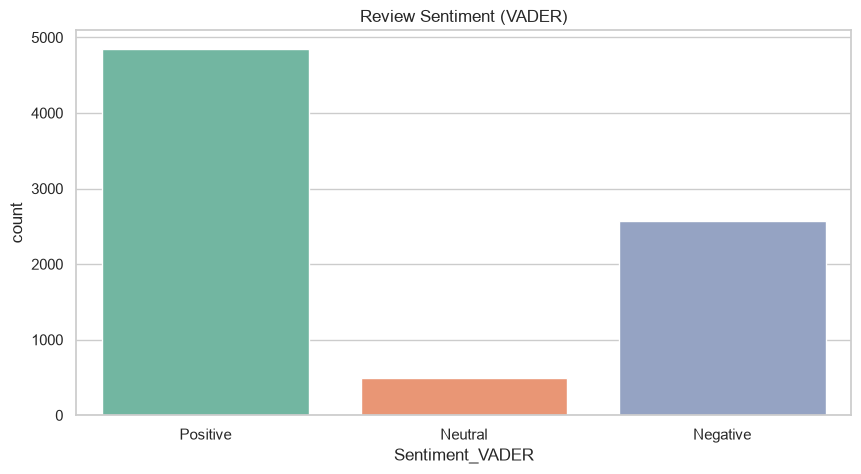

Sentiment_VADER
Positive    0.613
Negative    0.325
Neutral     0.062
Name: proportion, dtype: float64


In [16]:
order = ["Positive", "Neutral", "Negative"]
sns.countplot(data=reviews, x="Sentiment_VADER", order=order, hue="Sentiment_VADER", palette="Set2", legend=False)
plt.title("Review Sentiment (VADER)")
plt.show()
print(reviews["Sentiment_VADER"].value_counts(normalize=True).round(3))

**Observation:** _What share of reviews is positive? Name one limit of VADER, for example sarcasm or app-specific wording._

## 8. Sentiment by category
_Checklist: which categories have the most positive/negative sentiment?_

In [17]:
app_cat = apps.drop_duplicates("App")[["App", "Category"]]
merged = reviews.merge(app_cat, on="App", how="inner")
print("Reviews matched to a category:", len(merged), "of", len(reviews))

share = (pd.crosstab(merged["Category"], merged["Sentiment_VADER"], normalize="index")[order] * 100).round(1)
share = share.sort_values("Positive")
share

Reviews matched to a category: 7917 of 7917


Sentiment_VADER,Positive,Neutral,Negative
Category,,,
GAME,57.6,6.8,35.6
PRODUCTIVITY,58.0,8.1,34.0
LIFESTYLE,58.6,6.3,35.0
EDUCATION,58.6,6.1,35.3
SOCIAL,59.0,5.6,35.4
COMMUNICATION,59.1,7.9,33.0
FINANCE,61.4,7.9,30.7
TOOLS,61.7,6.5,31.8
HEALTH_AND_FITNESS,61.9,6.8,31.3


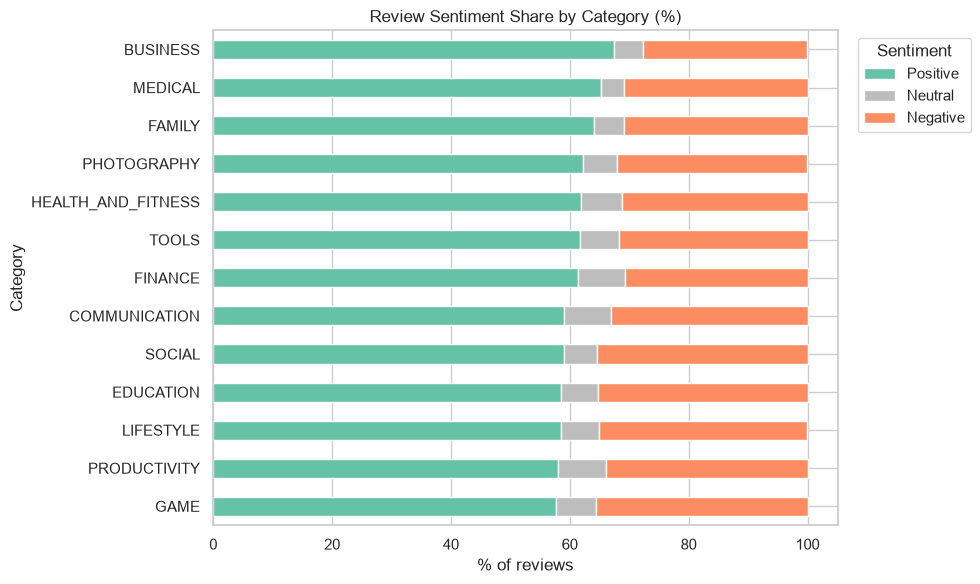

In [18]:
share.plot(kind="barh", stacked=True, figsize=(10, 6), color=["#66c2a5", "#bdbdbd", "#fc8d62"])
plt.title("Review Sentiment Share by Category (%)")
plt.xlabel("% of reviews")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Observation:** _Write 2-3 sentences about what this output shows._

## 9. Interactive visualisation (plotly)
_Checklist: at least one interactive chart_

In [19]:
app_stats = apps.dropna(subset=["Rating"]).copy()
app_stats["Log_Installs"] = np.log10(app_stats["Installs"])

fig = px.scatter(
    app_stats, x="Reviews", y="Rating", color="Category", size="Log_Installs",
    hover_name="App", hover_data=["Installs", "Type", "Price"],
    log_x=True, title="Apps: Reviews vs Rating (hover for details)",
)
fig.show()

**Observation:** _What can you see by hovering and filtering by category that a static chart would not show?_

## 10. Conclusion: 3 data-driven insights for a new developer
_Write 3 insights, each with the evidence behind it. Format suggestion:_

1. **Insight:** ... **Evidence:** ...
2. **Insight:** ... **Evidence:** ...
3. **Insight:** ... **Evidence:** ...

_Think about: which categories are crowded vs open, whether free or paid is the better model, whether size matters, and where users are happiest or unhappiest._